# Trabajo Práctico Nro. 2 - Transformada de Fourier y Procesamientos Básicos de Señales

Grupo 10, 2Q2026

Integrantes:

- Ana Negre
- Juan José Medina

In [199]:
pip install numpy matplotlib wget scipy control schemdraw --quiet


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Aplicación de la Transformada de Fourier
A continuación se computa la transformada de fourier en su forma computacional, con el fin de analizar tanto las señales reales obtenidas del trabajo práctico anterior como algunas de las señales base.

In [200]:
import numpy as np
import matplotlib.pyplot as plt

#### Obtención de archivos
En primer lugar, se obtienen los archivos correspondientes al ECG y PCG utilizados en el anterior trabajo, de la misma forma que fue detallado en el mismo.

[Fuente: Pshysio.net](https://physionet.org/content/ephnogram/1.0.0/MAT/#files-panel)

In [201]:
import os

URL = "https://physionet.org/files/ephnogram/1.0.0/MAT/"
FILE = "ECGPCG0010.mat"  # from 00 to 69

target_dir = "./data/"
os.makedirs(target_dir, exist_ok=True)

filepath = os.path.join(target_dir, FILE)

if not os.path.exists(filepath):
  !wget --no-check-certificate -P {target_dir} {URL}{FILE}

In [202]:
from scipy.io import loadmat

data = loadmat(os.path.join(target_dir, FILE))
print(data.keys())
ecg = data['ECG'].flatten()
pcg = data['PCG'].flatten()
fs = int(data['fs'].flatten()[0])

print(f"ECG length: {len(ecg)}, sampling rate: {fs} Hz")
print(f"ECG duration: {len(ecg)/fs:.1f} seconds")

print(f"PCG length: {len(pcg)}, sampling rate: {fs} Hz")
print(f"PCG duration: {len(pcg)/fs:.1f} seconds")


dict_keys(['__header__', '__version__', '__globals__', 'ECG', 'PCG', 'fs'])
ECG length: 14400000, sampling rate: 8000 Hz
ECG duration: 1800.0 seconds
PCG length: 14400000, sampling rate: 8000 Hz
PCG duration: 1800.0 seconds


Se observa que el sampling rate, o frecuencia de muestreo de las señales es de $8000 Hz$. Luego por teorema de muestreo, sabemos que:
$$x[n]=x_c(nT)=x_c(\frac{n}{f_s})$$

Si bien se trata de señales discretas, la resolución permite tomar las mismas como una señales continuas, y graficarlas como tal:

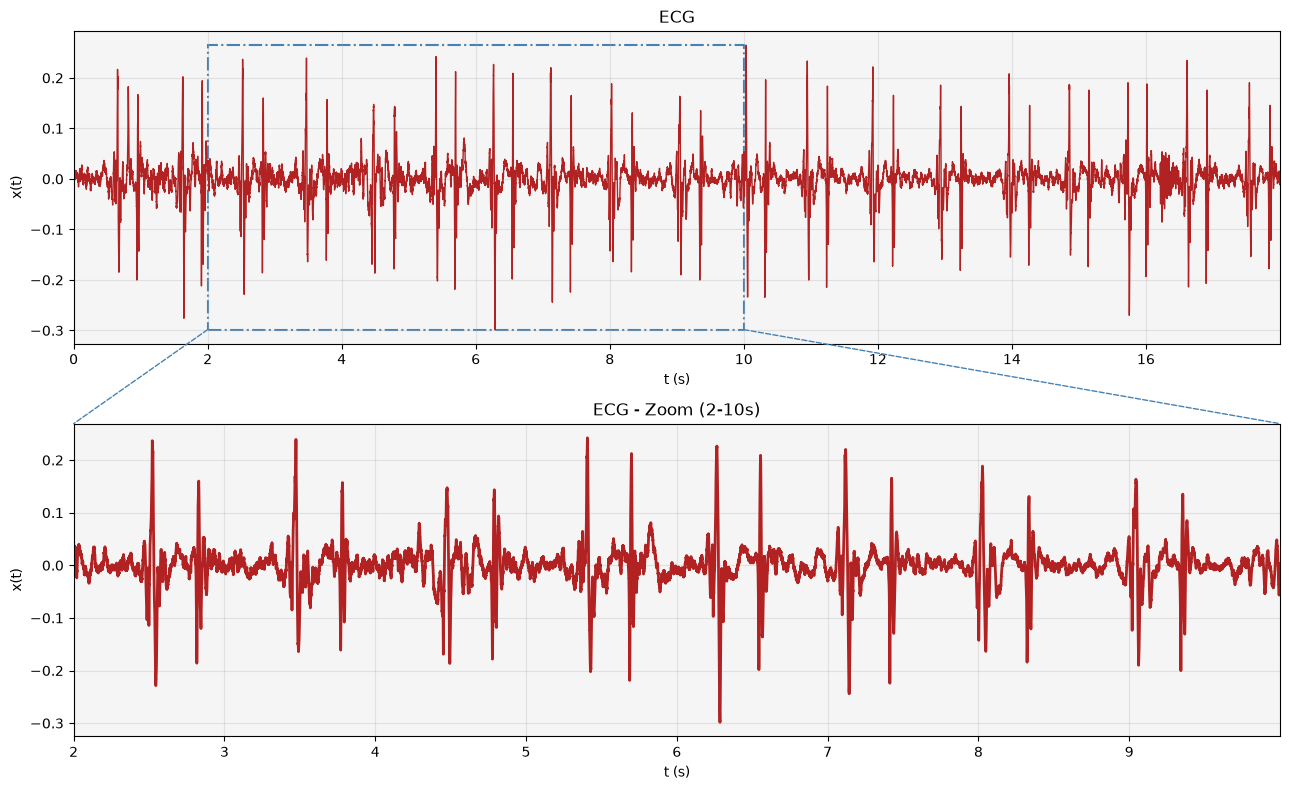

In [203]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle, ConnectionPatch

t = np.arange(len(ecg)) / fs
window = slice(0, int(fs * 18))
window_zoom = slice(int(fs * 2), int(fs * 10))  # subset de 8s

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), facecolor='white')

# grafico completo
ax1.set_facecolor('whitesmoke')
ax1.plot(t[window], pcg[window], linewidth=1, color="firebrick")
ax1.set_xlim(t[window].min(), t[window].max())
ax1.grid(True, alpha=0.3)
ax1.set_title('ECG')
ax1.set_xlabel('t (s)')
ax1.set_ylabel("x(t)")

# rectángulo para ver el zoom in
t_zoom_start = t[window_zoom].min()
t_zoom_end = t[window_zoom].max()
y_min, y_max = pcg[window].min(), pcg[window].max()
rect = Rectangle(
    (t_zoom_start, y_min), t_zoom_end - t_zoom_start, y_max - y_min,
    linewidth=1.5, edgecolor='steelblue', facecolor='none', linestyle='-.'
)
ax1.add_patch(rect)

# grafico zoom
ax2.set_facecolor('whitesmoke')
ax2.plot(t[window_zoom], pcg[window_zoom], linewidth=2, color="firebrick")
ax2.set_xlim(t[window_zoom].min(), t[window_zoom].max())
ax2.grid(True, alpha=0.3)
ax2.set_title('ECG - Zoom (2-10s)')
ax2.set_xlabel('t (s)')
ax2.set_ylabel("x(t)")
y_zoom_min, y_zoom_max = pcg[window_zoom].min(), pcg[window_zoom].max()

# conectores
con1 = ConnectionPatch(
    xyA=(t_zoom_start, y_min), coordsA=ax1.transData,
    xyB=(0, 1), coordsB=ax2.transAxes,
    color='steelblue', linestyle='--', linewidth=1
)

con2 = ConnectionPatch(
    xyA=(t_zoom_end, y_min), coordsA=ax1.transData,
    xyB=(1, 1), coordsB=ax2.transAxes,
    color='steelblue', linestyle='--', linewidth=1
)
fig.add_artist(con1)
fig.add_artist(con2)

plt.tight_layout()
# plt.show()

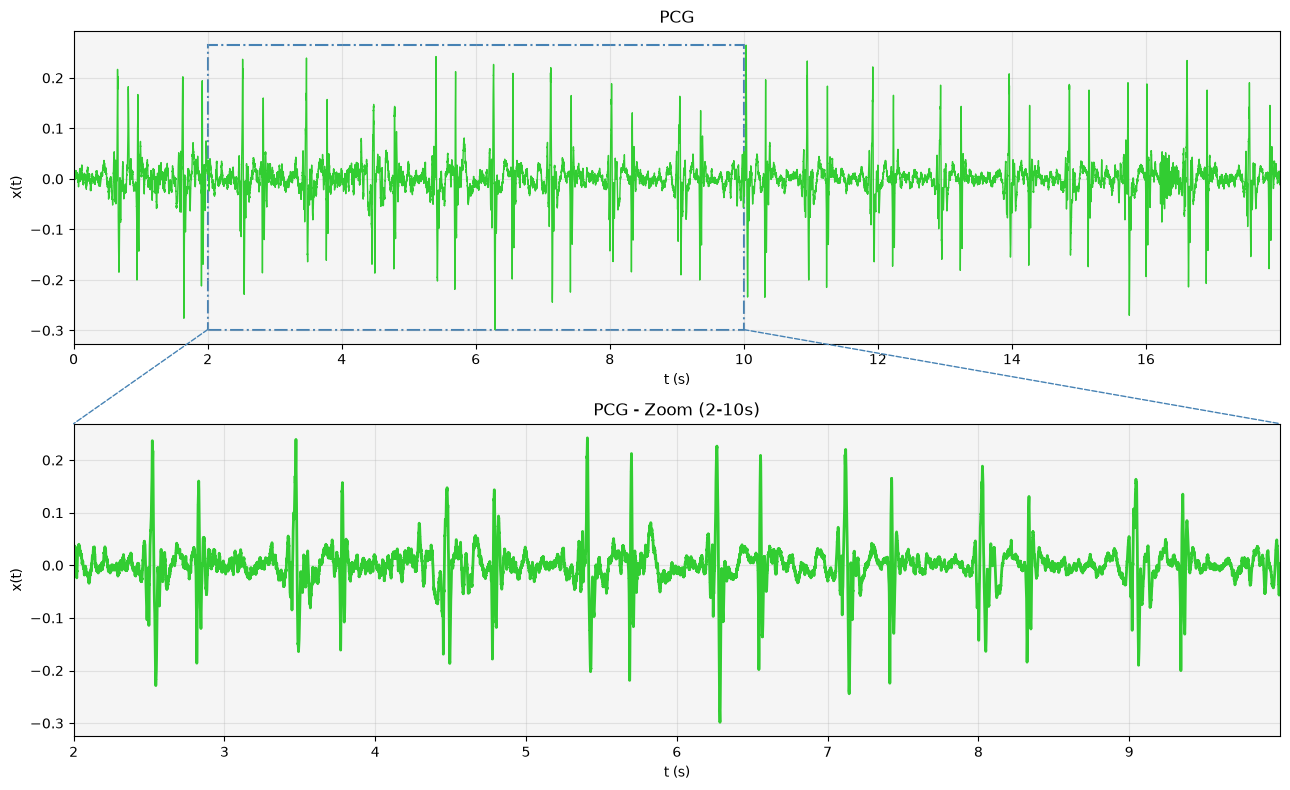

In [204]:
# @title
from matplotlib.patches import Rectangle, ConnectionPatch

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), facecolor='white')

# grafico completo
ax1.set_facecolor('whitesmoke')
ax1.plot(t[window], pcg[window], linewidth=1, color="limegreen")
ax1.set_xlim(t[window].min(), t[window].max())
ax1.grid(True, alpha=0.3)
ax1.set_title('PCG')
ax1.set_xlabel('t (s)')
ax1.set_ylabel("x(t)")

# rectángulo para ver el zoom in
t_zoom_start = t[window_zoom].min()
t_zoom_end = t[window_zoom].max()
y_min, y_max = pcg[window].min(), pcg[window].max()
rect = Rectangle(
    (t_zoom_start, y_min), t_zoom_end - t_zoom_start, y_max - y_min,
    linewidth=1.5, edgecolor='steelblue', facecolor='none', linestyle='-.'
)
ax1.add_patch(rect)

# grafico zoom
ax2.set_facecolor('whitesmoke')
ax2.plot(t[window_zoom], pcg[window_zoom], linewidth=2, color="limegreen")
ax2.set_xlim(t[window_zoom].min(), t[window_zoom].max())
ax2.grid(True, alpha=0.3)
ax2.set_title('PCG - Zoom (2-10s)')
ax2.set_xlabel('t (s)')
ax2.set_ylabel("x(t)")
y_zoom_min, y_zoom_max = pcg[window_zoom].min(), pcg[window_zoom].max()

# conectores
con1 = ConnectionPatch(
    xyA=(t_zoom_start, y_min), coordsA=ax1.transData,
    xyB=(0, 1), coordsB=ax2.transAxes,
    color='steelblue', linestyle='--', linewidth=1
)

con2 = ConnectionPatch(
    xyA=(t_zoom_end, y_min), coordsA=ax1.transData,
    xyB=(1, 1), coordsB=ax2.transAxes,
    color='steelblue', linestyle='--', linewidth=1
)
fig.add_artist(con1)
fig.add_artist(con2)

plt.tight_layout()
# plt.show()

Luego se puede muestrear las señales de PCG y ECG, observando que dado que el período de muestreo de las señales es: $\frac{1}{fs}=0.000125s$, el período elegido de muestreo debe ser igual o superior al mismo.
Se elige $T=0.5$.

A continuación se grafican las señales discretas obtenidas, recortando lo obtenido a $2-4s$ para simplificar la visualización. No se explicita el método de muestreo ideal via conversor A/D puesto a que ya fue detallado en el trabajo anterior.

In [205]:
def hacer_x_c_desde_array(t_data, x_data):
    def x_c(t_eval):
        return np.interp(t_eval, t_data, x_data)
    return x_c

def plot_señal_muestreada(x_c, t, T, titulo_senal=r'$x_c(t)$', figsize=(8, 4),color='limegreen'):
    step = t[1] - t[0]
    N = int(round(T / step))

    t_n = t[::N]
    n = np.arange(len(t_n))
    xc_cont = x_c(t)
    xc_en_tn = xc_cont[::N]

    fig, ax = plt.subplots(1, 1, figsize=figsize)

    markerline, stemlines, baseline = ax.stem(n, xc_en_tn, basefmt=" ")
    plt.setp(markerline, color=color)
    plt.setp(stemlines, color=color)
    ax.set_title(titulo_senal)
    ax.set_xlabel('n')
    ax.grid(True)

    plt.tight_layout()
    return fig, ax, (n, t_n, xc_en_tn)

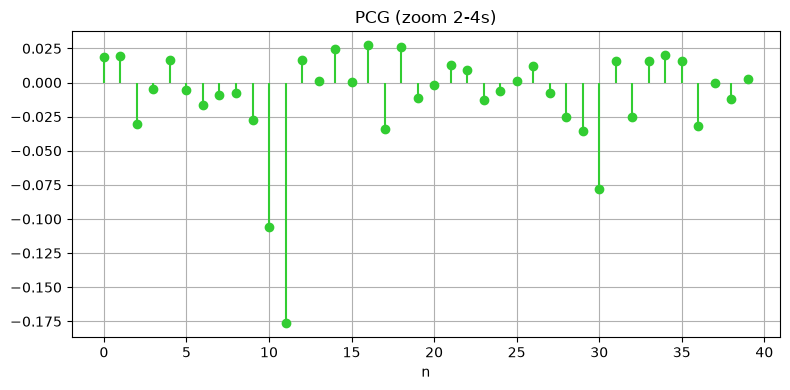

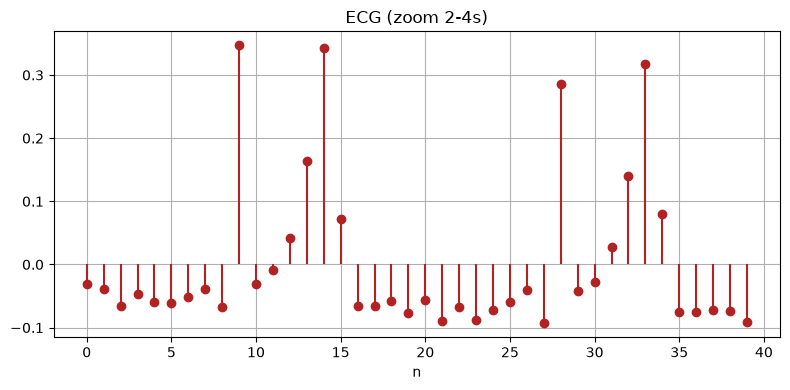

In [206]:
fs = 8000
t = np.arange(len(pcg)) / fs

window = slice(int(fs*2), int(fs*4))
t_win = t[window]
pcg_win = pcg[window]

x_c_pcg_win = hacer_x_c_desde_array(t_win, pcg_win)
fig, axs, (n, t_n, xn) = plot_señal_muestreada(x_c_pcg_win, t_win, T=0.05, titulo_senal='PCG (zoom 2-4s)',figsize=(8,4),color='limegreen')

ecg_win = ecg[window]
x_c_ecg_win = hacer_x_c_desde_array(t_win, ecg_win)
fig, axs, (n, t_n, xn) = plot_señal_muestreada(x_c_ecg_win, t_win, T=0.05, titulo_senal='ECG (zoom 2-4s)',figsize=(8,4),color='firebrick')


#### Transformada de Fourier

A partir de las señales discretas obtenidas, puede aplicarse la transformada de Fourier de tiempo discreto para obtener la información de la señal en términos de frecuencia.
Para obtener la DTFT de una señal, debe hacerse:
$$
  \hat{X}=\mathcal{F}_d\{x[n]\}(f)=\sum_{n=-\infty}^{+\infty}x[n]e^{-i2\pi f_d n}
$$
Esta expresión presenta distintos problemas de implementación, dado que _no_ es computable. En primer lugar, la sumatoria exige una cantidad infinita de muestras, con lo cual no es compatible con señales reales (sin descripción analítica). Por el otro lado, la DTFT trabaja con frecuencia continua, lo cual implica un problema de implementación, ya que no pueden almacenarse todas las frecuencias.

Luego puede proponerse la DFT como solución a estos problemas. La idea es "muestrear" la DTFT a partir de una cantidad N de muestras:
$$
X[k]=\sum_{n=0}^{N-1}x[n]e^{-i2\pi f_k n}\qquad f_k=\frac{k}{N}, k\in \{0,...,N-1\}
$$
De esta manera, se pasa a trabajar con secuencias finitas y espectro en variable discreta, aproximando así la transformada de Fourier de tiempo discreto.
En particular, puede utilizarse el algoritmo FFT para calcular DFT.

Luego puede aplicarse este algoritmo para computar la transformada de las señalkes de PCG y ECG. Cabe aclarar que para esto es necesario que las señales sean de _largo finito_, lo cual estas señales cumplen dado que son señales reales no definidas fuera del tiempo observado.
Para acortar el tiempo de ejecución, se toma la ventana utilizada previamente de $8s$ para computar la DFT de las señales de PCG y ECG.

In [207]:
## referencia de: https://agustinsolano.github.io/SyS_scriptsbook/md_scripts/Computo_TFourier_FFT_senial_real.html

import numpy as np
import matplotlib.pyplot as plt

def dtft_muestreada(x, fs, nfft=None):
    x = np.asarray(x)
    if nfft is None:
        nfft = len(x) # default es N, cantidad de muestras

    X = np.fft.fftshift(np.fft.fft(x, n=nfft))
    k = np.arange(-(nfft // 2), nfft - nfft // 2)
    f = k * fs / nfft
    return f, X

def plot_dtft(x, fs, nfft=None, titulo='PCG', umbral_fase=1e-3, fmax=500, color='C0'):
    f, X = dtft_muestreada(x, fs, nfft)
    sel = np.abs(f) <= fmax
    f_p, X_p = f[sel], X[sel]

    mag = np.abs(X_p)
    fase = np.angle(X_p)
    fase[mag < umbral_fase * mag.max()] = 0

    fig, axs = plt.subplots(2, 1, figsize=(12, 8))

    ml, sl, _ = axs[0].stem(f_p, mag, basefmt=" ")
    plt.setp(ml, color=color, markersize=3); plt.setp(sl, color=color, linewidth=0.8)
    axs[0].set_title(rf'{titulo} - $|X(f_k)|$')
    axs[0].set_ylabel('Magnitud [u.a.]'); axs[0].grid(True)
    axs[0].set_xlabel('Frecuencia [Hz]')

    ml, sl, _ = axs[1].stem(f_p, fase, basefmt=" ")
    plt.setp(ml, color=color, markersize=3); plt.setp(sl, color=color, linewidth=0.8)
    axs[1].set_title(rf'{titulo} - $\angle X(f_k)$')
    axs[1].set_ylabel('Fase [rad]')
    axs[1].set_xlabel('Frecuencia [Hz]')
    axs[1].grid(True)

    axs[0].set_xlim(-fmax, fmax)
    plt.tight_layout()
    return fig, axs, (f, X)      # devuelve el espectro completo, no solo el recortado

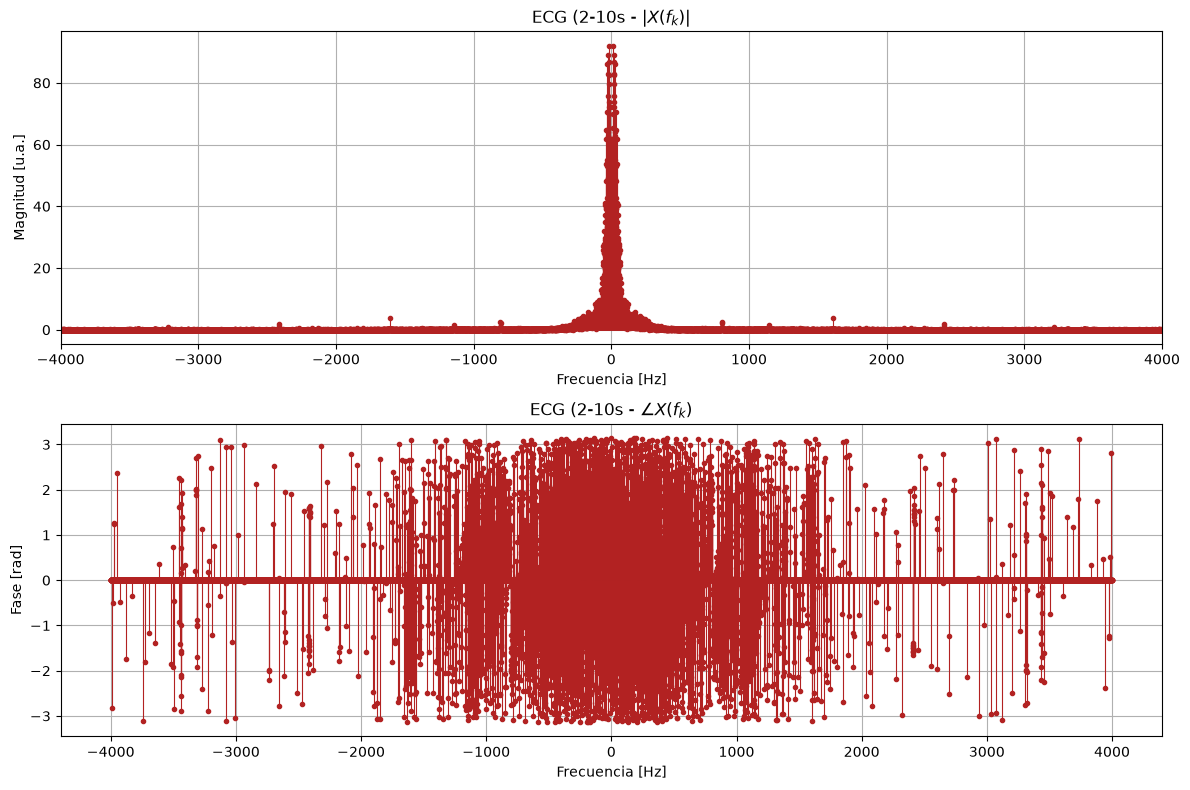

In [208]:
fig, axs, (f, X) = plot_dtft(pcg_win, fs, titulo='ECG (2-10s', fmax=fs/2,color='firebrick')

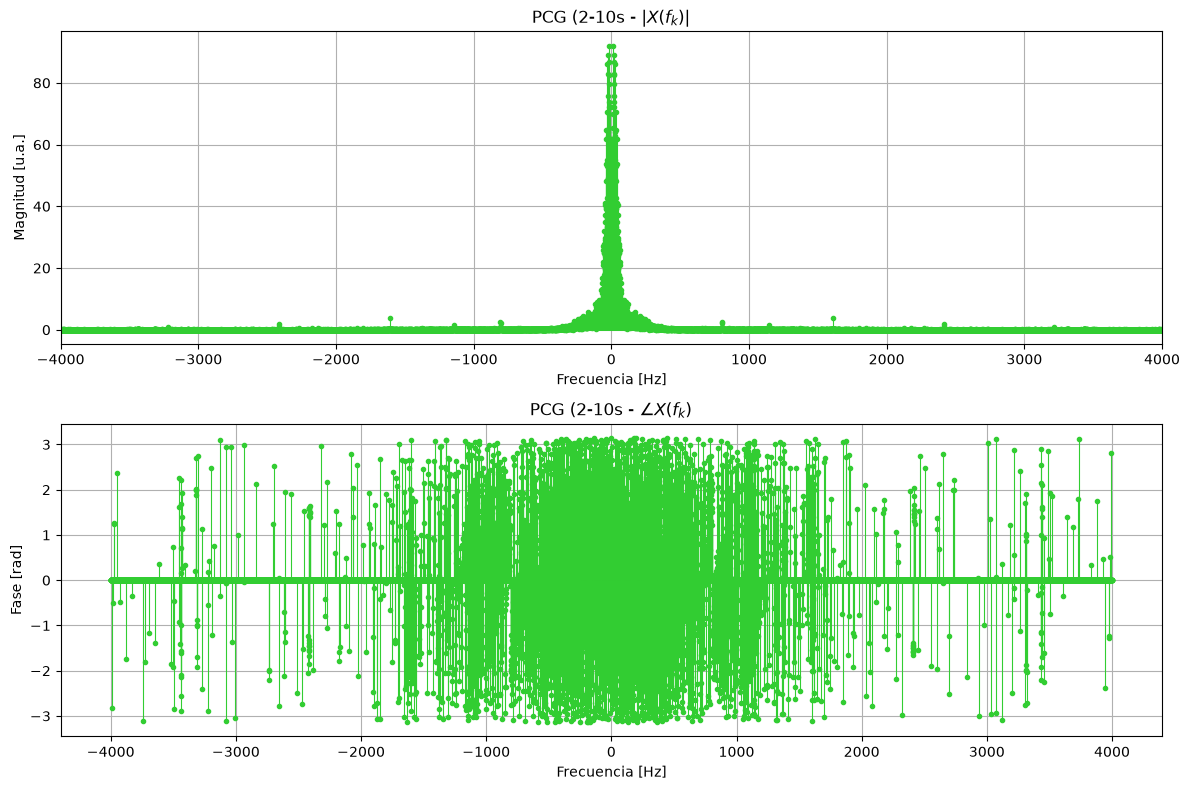

In [209]:
fig, axs, (f, X) = plot_dtft(pcg_win, fs, titulo='PCG (2-10s', fmax=fs/2,color='limegreen')

#### Análisis de ECG y PCG
A partir de la DFT de las señales, podemos observar que el contenido de las mismas en términos de frecuencia se concentra alrededor

## Implementación de Procesamientos Básicos

## Modelado de sistema a partir de circuito RLC
